# 03 · Feature Engineering y Segmentación de Gamas


**Objetivo.** Construir las variables derivadas necesarias para responder los tres objetivos del proyecto a partir del dataset limpio (`data/clean/falabella_cleaned.csv`, 1,037 registros y 8 columnas) y generar el dataset procesado final (`data/processed/falabella_processed.csv`, 1,037 registros y 16 columnas), garantizando **0 % de valores nulos (NA)** en todas las variables.

La implementación modular se encuentra en [`pipeline/processing_data.py`](../pipeline/processing_data.py) y es invocada por `pipeline/main.py` mediante `processing_data.run()`.

| # | Grupo de Variables | Variables Creadas | Propósito Analítico |
|---|---|---|---|
| 1 | Descuentos | `has_discount`, `discount_amount`, `discount_pct` | Cuantificar la presencia y magnitud absoluta/porcentual de las rebajas (Objetivo 1) |
| 2 | Segmentación de Gamas | `prices_category` (`low`, `mid`, `high`) | Estratificar cada categoría por terciles empíricos de precio contrastados con el mercado (Objetivos 1, 2 y 3) |
| 3 | Clasificación de Vendedores | `seller_type` (`FALABELLA_DIRECT`, `MARKETPLACE_SELLER`) | Contrastar la competitividad de Falabella y filiales frente a terceros (Objetivo 2) |
| 4 | Banderas y Especificaciones (Regex) | `is_refurbished`, `is_bundle`, `inches` | Aislar reacondicionados, combos promocionales y tamaño de pantalla en televisores (Objetivos 1 y 3) |

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "pipeline"))

import processing_data as fe

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)

CATS = ["laptops", "phones", "tvs"]
TIERS = ["low", "mid", "high"]
FIG_DOCS = ROOT / "docs" / "img"
FIG_ANA = ROOT / "data" / "analysis" / "figures"
FIG_DOCS.mkdir(parents=True, exist_ok=True)
FIG_ANA.mkdir(parents=True, exist_ok=True)


def say(text):
    display(Markdown(text))


def savefig(name):
    plt.savefig(FIG_DOCS / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.savefig(FIG_ANA / f"{name}.png", dpi=160, bbox_inches="tight")


clean = fe.load_clean()
print(f"Dataset limpio cargado: {clean.shape[0]} filas x {clean.shape[1]} columnas")
display(clean.head())

Dataset limpio cargado: 1037 filas x 8 columnas


,product,brand,category,seller,list_price,internet_price,list_price_imputed,is_price_outlier
0,CELULAR REDMI NOTE 17 PRO MAX 5G BLACK + AUDÍFONOS REDMI NEO,XIAOMI,phones,FALABELLA,2199.0,1899.0,0,0
1,NOTE 17 PRO 5G NEGRO + AUDÍFONOS BLANCOS,XIAOMI,phones,FALABELLA,1799.0,1499.0,0,0
2,IPHONE 18 PRO MAX 256GB,APPLE,phones,FALABELLA,7299.0,6999.0,0,1
3,IPHONE 18 PRO 256GB,APPLE,phones,FALABELLA,6699.0,6499.0,0,1
4,GALAXY S26 FE 128 GB BLACK,SAMSUNG,phones,FALABELLA,3399.0,2899.0,0,0


## 1. Variables de Descuento (`has_discount`, `discount_amount`, `discount_pct`)

Para evaluar la magnitud y distribución de las rebajas entre el precio de lista (`list_price`) y el precio vigente por internet (`internet_price`), se construyen tres variables complementarias:

- **`has_discount`** (`int8`, binario `0`/`1`): vale `1` cuando `list_price > internet_price` y `0` cuando el producto no presenta descuento (`list_price == internet_price`, correspondientes a las 36 publicaciones cuyo `list_price` fue imputado en la etapa de limpieza).
- **`discount_amount`** (`float64`, en S/): ahorro nominal en soles, definido como $\text{list\_price} - \text{internet\_price}$.
- **`discount_pct`** (`float64`, en %): rebaja relativa porcentual respecto al precio de lista:
$$\text{discount\_pct} = \frac{\text{list\_price} - \text{internet\_price}}{\text{list\_price}} \times 100$$

In [2]:
df = fe.add_discount_features(clean)

resumen_desc = df.groupby("category").agg(
    publicaciones=("product", "size"),
    con_descuento=("has_discount", "sum"),
    pct_con_descuento=("has_discount", lambda s: round(s.mean() * 100, 1)),
    mediana_desc_pct=("discount_pct", "median"),
    iqr_desc_pct=("discount_pct", lambda s: round(s.quantile(0.75) - s.quantile(0.25), 2)),
    mediana_ahorro_soles=("discount_amount", "median"),
    max_desc_pct=("discount_pct", "max"),
).loc[CATS]
display(resumen_desc)

say(
    f"**Lectura.** El **{df.has_discount.mean():.1%}** del catálogo limpio ({int(df.has_discount.sum())} de {len(df)} publicaciones) "
    f"muestra un precio de lista superior al precio internet. Los televisores presentan la mediana de descuento porcentual más alta "
    f"(**{resumen_desc.loc['tvs', 'mediana_desc_pct']:.2f} %**), seguidos por celulares (**{resumen_desc.loc['phones', 'mediana_desc_pct']:.2f} %**) "
    f"y laptops (**{resumen_desc.loc['laptops', 'mediana_desc_pct']:.2f} %**). En términos absolutos, las laptops lideran el ahorro mediano "
    f"con **S/ {resumen_desc.loc['laptops', 'mediana_ahorro_soles']:,.0f}** por equipo."
)

,publicaciones,con_descuento,pct_con_descuento,mediana_desc_pct,iqr_desc_pct,mediana_ahorro_soles,max_desc_pct
category,,,,,,,
laptops,433,417,96.3,18.82,18.44,1000.0,92.88
phones,437,422,96.6,24.88,20.21,401.0,66.89
tvs,167,162,97.0,34.80,22.99,801.0,68.01


**Lectura.** El **96.5%** del catálogo limpio (1001 de 1037 publicaciones) muestra un precio de lista superior al precio internet. Los televisores presentan la mediana de descuento porcentual más alta (**34.80 %**), seguidos por celulares (**24.88 %**) y laptops (**18.82 %**). En términos absolutos, las laptops lideran el ahorro mediano con **S/ 1,000** por equipo.

## 2. Segmentación de Gamas de Precio (`prices_category`: `low`, `mid`, `high`)

**Criterio metodológico.** Un mismo precio en soles tiene significados opuestos según el tipo de equipo (por ejemplo, S/ 2,500 corresponde a una laptop de entrada pero a un celular de gama alta). Por ello, la variable `prices_category` se construye calculando los **terciles empíricos (percentiles 33.3 % y 66.7 %)** de `internet_price` de forma **independiente dentro de cada categoría limpia**:

- **`low` (Gama de entrada):** $\text{internet\_price} \le P_{33.3}$ de su categoría.
- **`mid` (Gama media):** $P_{33.3} < \text{internet\_price} \le P_{66.7}$ de su categoría.
- **`high` (Gama alta / premium):** $\text{internet\_price} > P_{66.7}$ de su categoría.

**Contraste con rangos comerciales del mercado retail peruano.** Los umbrales obtenidos por terciles empíricos coinciden estrechamente con la segmentación estándar del retail tecnológico en Perú:
- En **celulares (`phones`)**, el corte $P_{33.3} = \text{S/ } 892$ separa los equipos básicos/entrada ($< \text{S/ } 900$) de la gama media ($\text{S/ } 900 - \text{S/ } 2,126$), mientras que $P_{66.7} = \text{S/ } 2,126$ marca el inicio de la gama alta y flagships ($> \text{S/ } 2,100$).
- En **laptops (`laptops`)**, el corte $P_{33.3} = \text{S/ } 3,199$ delimita las portátiles de ofimática/estudio (Core i3/i5 o Ryzen 3/5 de entrada), la franja media ($\text{S/ } 3,200 - \text{S/ } 4,699$) agrupa equipos corporativos y gamer de entrada (RTX 3050/4050), y $P_{66.7} = \text{S/ } 4,699$ aísla estaciones gamer avanzadas y MacBooks Pro/Air.
- En **televisores (`tvs`)**, el corte $P_{33.3} = \text{S/ } 1,489$ separa televisores HD/FHD y 4K de 32"–50", la gama media ($\text{S/ } 1,490 - \text{S/ } 1,999$) concentra los paneles 4K QLED/NanoCell de 55"–65", y $P_{66.7} = \text{S/ } 1,999$ distingue los paneles OLED, MiniLED y formatos de 75" a 100".

,category,min_price,p33_cutoff,median_price,p66_cutoff,max_price,low_count,mid_count,high_count
0,laptops,835.0,3199.00,3739.0,4699.00,27345.56,155,136,142
1,phones,79.9,892.33,1399.0,2125.67,8999.00,146,145,146
2,tvs,283.9,1489.00,1729.0,1999.00,9999.00,57,55,55


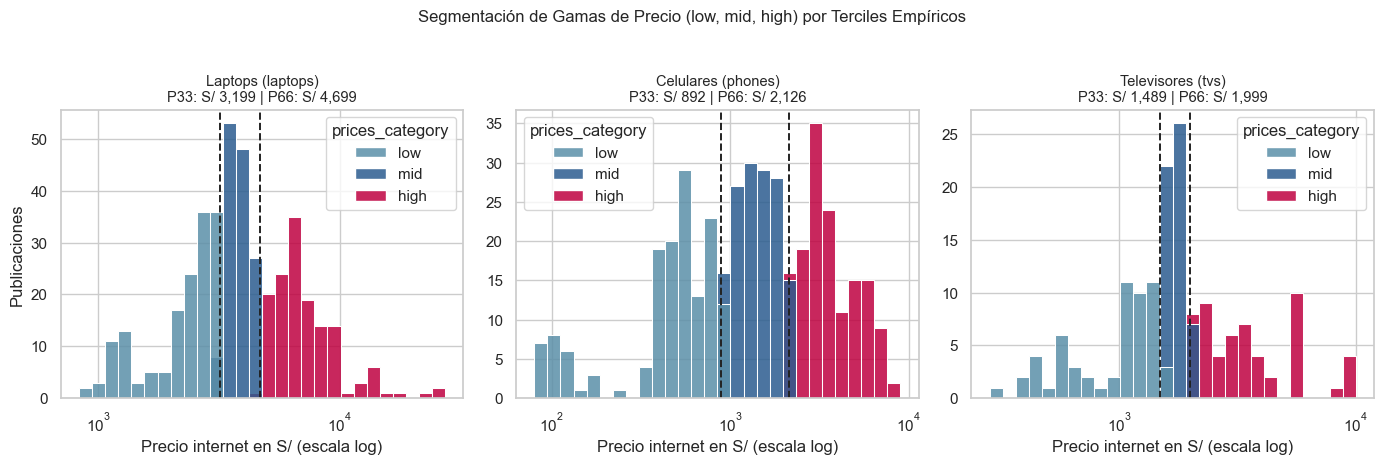

In [3]:
df = fe.add_price_category(df)
umbrales = fe.get_price_tier_thresholds(df)
display(umbrales)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=False)
palette_tiers = {"low": "#5b8fa8", "mid": "#2b5c8f", "high": "#bf0140"}
titulos = {"laptops": "Laptops (laptops)", "phones": "Celulares (phones)", "tvs": "Televisores (tvs)"}

for ax, cat in zip(axes, CATS):
    sub = df[df["category"] == cat]
    row = umbrales[umbrales["category"] == cat].iloc[0]
    sns.histplot(
        data=sub, x="internet_price", hue="prices_category", hue_order=TIERS,
        palette=palette_tiers, bins=28, alpha=0.85, ax=ax, log_scale=True
    )
    ax.axvline(row["p33_cutoff"], color="#222222", linestyle="--", linewidth=1.4)
    ax.axvline(row["p66_cutoff"], color="#222222", linestyle="--", linewidth=1.4)
    ax.set_title(f"{titulos[cat]}\nP33: S/ {row['p33_cutoff']:,.0f} | P66: S/ {row['p66_cutoff']:,.0f}", fontsize=10.5)
    ax.set_xlabel("Precio internet en S/ (escala log)")
    ax.set_ylabel("Publicaciones" if cat == "laptops" else "")

plt.suptitle("Segmentación de Gamas de Precio (low, mid, high) por Terciles Empíricos", fontsize=12, y=1.03)
plt.tight_layout()
savefig("fe_01_gamas_terciles")
plt.show()

## 3. Clasificación de Vendedores (`seller_type`)

Para responder al Objetivo 2 (competitividad tarifaria entre el retail directo y los vendedores externos), se agrupa la variable `seller` en dos categorías operativas:

- **`FALABELLA_DIRECT`**: ventas directas operadas por el grupo Falabella y sus filiales oficiales en el país (`FALABELLA`, `TOTTUS` y `SODIMAC`).
- **`MARKETPLACE_SELLER`**: los 183 vendedores terceros independientes que comercializan sus productos a través de la plataforma.

In [4]:
df = fe.add_seller_type(df)

tabla_sellers = pd.crosstab(df["category"], df["seller_type"], margins=True).loc[CATS + ["All"]]
tabla_sellers["% FALABELLA_DIRECT"] = (tabla_sellers["FALABELLA_DIRECT"] / tabla_sellers["All"] * 100).round(1)
display(tabla_sellers)

say(
    f"**Resultado.** Las ventas directas del grupo (`FALABELLA_DIRECT`) representan **155 publicaciones (14.9 %)** del catálogo limpio, "
    f"mientras que los terceros (`MARKETPLACE_SELLER`) concentran **882 publicaciones (85.1 %)**. La presencia directa del grupo es "
    f"mucho más alta en televisores (**{tabla_sellers.loc['tvs', '% FALABELLA_DIRECT']} %**) que en celulares "
    f"(**{tabla_sellers.loc['phones', '% FALABELLA_DIRECT']} %**) y laptops (**{tabla_sellers.loc['laptops', '% FALABELLA_DIRECT']} %**)."
)

seller_type,FALABELLA_DIRECT,MARKETPLACE_SELLER,All,% FALABELLA_DIRECT
category,,,,
laptops,39,394,433,9.0
phones,57,380,437,13.0
tvs,59,108,167,35.3
All,155,882,1037,14.9


**Resultado.** Las ventas directas del grupo (`FALABELLA_DIRECT`) representan **155 publicaciones (14.9 %)** del catálogo limpio, mientras que los terceros (`MARKETPLACE_SELLER`) concentran **882 publicaciones (85.1 %)**. La presencia directa del grupo es mucho más alta en televisores (**35.3 %**) que en celulares (**13.0 %**) y laptops (**9.0 %**).

## 4. Extracción de Banderas y Especificaciones mediante Expresiones Regulares (`is_refurbished`, `is_bundle`, `inches`)

A partir del texto normalizado de `product` se extraen tres variables estructuradas mediante expresiones regulares:

1. **`is_refurbished`** (`int8`, `0`/`1`): identifica equipos reacondicionados o de segunda selección buscando los patrones `REACONDICIONADO`, `REACONDICIONADA`, `OPEN BOX`, `REFURBISHED` o `SEMI NUEVO`. Es indispensable para no confundir iPhones o ThinkPads reacondicionados con precios de equipos nuevos.
2. **`is_bundle`** (`int8`, `0`/`1`): identifica ofertas en combo o paquete promocional (`COMBO`, `PACK`, `KIT`, `REGALO`, `OBSEQUIO`, o el signo `+` seguido de un accesorio como `+ AUDÍFONOS`, `+ MOCHILA`, `+ MOUSE`, `+ PARLANTE`, `+ BARRA DE SONIDO`). La expresión regular excluye explícitamente el uso técnico del signo `+` en especificaciones de memoria o pantalla (`8+256GB`, `16GB RAM + 1TB SSD`, `FHD+`, `SIM + ESIM`).
3. **`inches`** (`int64`, en pulgadas): extrae numéricamente la diagonal de pantalla en televisores (`32`, `43`, `50`, `55`, `65`, `75`, `85`, etc.). En los 167 televisores del dataset limpio se alcanza **100 % de extracción exitosa (0 fallos)**. Para los registros de `phones` y `laptops` se codifica con `0` (*no aplica*), cumpliendo estrictamente la regla de **0 % de valores nulos (NA)** en todas las columnas del CSV procesado.

In [5]:
df = fe.add_product_flags_and_specs(df)

resumen_flags = df.groupby("category").agg(
    total=("product", "size"),
    reacondicionados=("is_refurbished", "sum"),
    pct_reacond=("is_refurbished", lambda s: round(s.mean() * 100, 1)),
    combos_bundle=("is_bundle", "sum"),
    pct_bundle=("is_bundle", lambda s: round(s.mean() * 100, 1)),
    tvs_con_pulgadas=("inches", lambda s: int((s > 0).sum())),
).loc[CATS]
display(resumen_flags)

tvs_inches = df[df["category"] == "tvs"]["inches"].value_counts().sort_index()
print("Distribución de tamaños de pantalla (inches) en los 167 televisores:")
display(tvs_inches.rename("publicaciones").to_frame().T)

,total,reacondicionados,pct_reacond,combos_bundle,pct_bundle,tvs_con_pulgadas
category,,,,,,
laptops,433,17,3.9,20,4.6,0
phones,437,76,17.4,52,11.9,0
tvs,167,0,0.0,25,15.0,167


Distribución de tamaños de pantalla (inches) en los 167 televisores:


inches,15,32,40,43,50,55,60,65,70,75,77,85,86,98,100
publicaciones,1,15,3,16,8,30,2,53,2,19,1,9,1,4,3


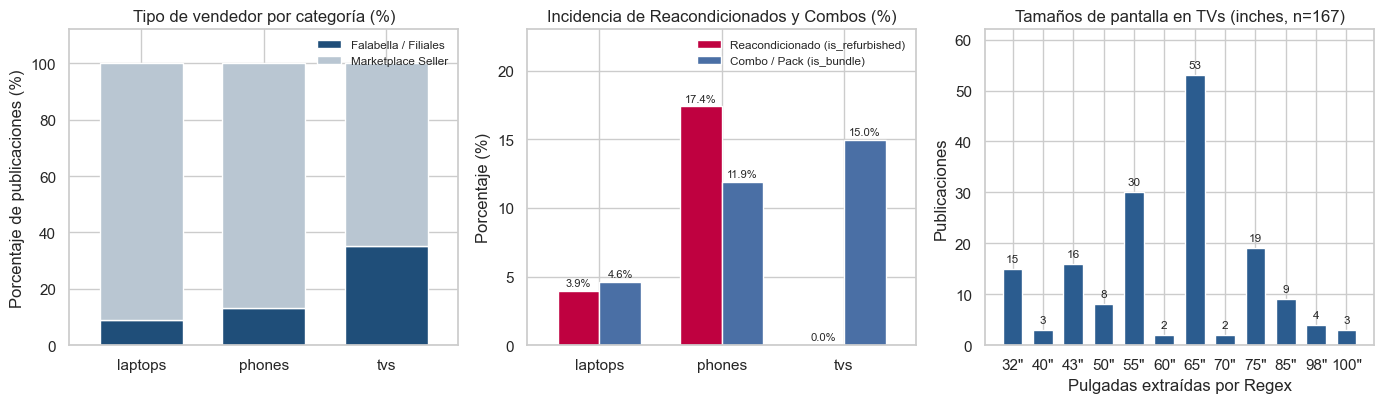

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

# Panel 1: Seller type por categoría
ct_seller = pd.crosstab(df["category"], df["seller_type"], normalize="index").loc[CATS] * 100
ct_seller.plot(kind="bar", stacked=True, ax=axes[0], color=["#1f4e79", "#b9c6d2"], width=0.68, rot=0)
axes[0].set_title("Tipo de vendedor por categoría (%)")
axes[0].set_xlabel("")
axes[0].set_ylabel("Porcentaje de publicaciones (%)")
axes[0].legend(["Falabella / Filiales", "Marketplace Seller"], frameon=False, loc="upper right", fontsize=8.5)
axes[0].set_ylim(0, 112)

# Panel 2: Banderas is_refurbished e is_bundle por categoría
flags_pct = pd.DataFrame({
    "Reacondicionado (is_refurbished)": df.groupby("category")["is_refurbished"].mean() * 100,
    "Combo / Pack (is_bundle)": df.groupby("category")["is_bundle"].mean() * 100,
}).loc[CATS]
flags_pct.plot(kind="bar", ax=axes[1], color=["#bf0140", "#4a6fa5"], width=0.68, rot=0)
for cont in axes[1].containers:
    axes[1].bar_label(cont, fmt="%.1f%%", fontsize=8, padding=2)
axes[1].set_title("Incidencia de Reacondicionados y Combos (%)")
axes[1].set_xlabel("")
axes[1].set_ylabel("Porcentaje (%)")
axes[1].set_ylim(0, 23)
axes[1].legend(frameon=False, fontsize=8.5)

# Panel 3: Distribución de pulgadas en TVs
principales_pulg = tvs_inches[tvs_inches >= 2]
axes[2].bar(principales_pulg.index.astype(str) + '"', principales_pulg.values, color="#2b5c8f", width=0.65)
for idx, val in enumerate(principales_pulg.values):
    axes[2].text(idx, val + 1, str(val), ha="center", va="bottom", fontsize=8.5)
axes[2].set_title("Tamaños de pantalla en TVs (inches, n=167)")
axes[2].set_xlabel("Pulgadas extraídas por Regex")
axes[2].set_ylabel("Publicaciones")
axes[2].set_ylim(0, 62)

plt.tight_layout()
savefig("fe_02_banderas_y_vendedores")
plt.show()

## 5. Verificación del Pipeline y Exportación (`falabella_processed.csv`)

Se ejecuta `fe.run()` para generar `data/processed/falabella_processed.csv`, comprobando que el resultado paso a paso del notebook sea idéntico al del script y que **ninguna de las 16 columnas tenga valores nulos (0 % NA)**.

In [7]:
processed = fe.run()
pd.testing.assert_frame_equal(
    processed.astype({"category": str, "prices_category": str, "seller_type": str}),
    df.astype({"category": str, "prices_category": str, "seller_type": str}),
    check_dtype=False,
)

verificacion = pd.DataFrame({
    "tipo": processed.dtypes.astype(str),
    "nulos": processed.isna().sum(),
    "% nulos": (processed.isna().mean() * 100).round(2),
    "valores_distintos": processed.nunique(),
    "minimo": processed.min(numeric_only=True),
    "maximo": processed.max(numeric_only=True),
})
display(verificacion)
print(f"OK: data/processed/falabella_processed.csv guardado ({processed.shape[0]} filas x {processed.shape[1]} columnas, 0 nulos)")

,tipo,nulos,% nulos,valores_distintos,minimo,maximo
brand,str,0,0.0,40,NaN,NaN
category,str,0,0.0,3,NaN,NaN
discount_amount,float64,0,0.0,380,0.0,74300.00
discount_pct,float64,0,0.0,682,0.0,92.88
has_discount,int8,0,0.0,2,0.0,1.00
inches,int64,0,0.0,16,0.0,100.00
internet_price,float64,0,0.0,461,79.9,27345.56
is_bundle,int8,0,0.0,2,0.0,1.00
is_price_outlier,int64,0,0.0,2,0.0,1.00
is_refurbished,int8,0,0.0,2,0.0,1.00


OK: data/processed/falabella_processed.csv guardado (1037 filas x 16 columnas, 0 nulos)
